# 01 — Exploratory Data Analysis of OpenParlData

**Purpose.** Build a comprehensive picture of the parliamentary affairs
corpus available under `data/`, in preparation for the topic-classification
service. We answer:

- Which parliaments are represented, and how many affairs does each have?
- What harmonized affair types (Motion, Postulate, Interpellation, ...)
  are used by each parliament?
- What languages are titles and full texts available in?
- How long are the texts / documents / speeches, and how are they
  distributed across bodies and types?
- For the labelled HackApertus subset: what subject-area schemes exist,
  and how are affairs distributed across them?
- For the DVS use case: how are the 3,433 PolitMonitor-tagged
  digitalisation affairs distributed across parliaments and time?

**Inputs.**

- `data/exports/index.json` — top-level corpus inventory
- `data/exports/affairs.ndjson.gz` — 326,396 affairs (master table)
- `data/exports/texts/*.ndjson.gz` — 226,078 affair texts
- `data/exports/docs/*.ndjson.gz` — 910,298 documents (Tika-extracted text)
- `data/exports/speeches/*.ndjson.gz` — 552,563 speeches
- `data/exports/news/*.ndjson.gz` — 339,562 news items
- `data/hackapertus/*.csv / .xlsx` — labelled subsets (CHE + SG/TG/Zug/ZH,
  PolitMonitor digitalisation, APS scheme)

**Outputs.**

- `data/eda/affairs_by_body_type.parquet` — body × type counts
- `data/eda/texts_stats.parquet` — body × text-type × language length stats
- `data/eda/docs_stats.parquet` — body-level docs aggregates
- `data/eda/speeches_stats.parquet` — body-level speeches aggregates
- `data/eda/news_stats.parquet` — body-level news aggregates
- `Log.md` entry per AGENTS.md §8

**Conventions.** Per AGENTS.md §6: `PROJECT_ROOT` is derived from the
notebook location; all paths are `pathlib.Path`; reusable logic lives in
`src/eda_io.py`; HTML stripping is approximate (regex-based); the heavy
scans cache their aggregated output so re-runs are fast (set
`USE_CACHE=False` to force a rescan).

## Setup

In [1]:
from __future__ import annotations

import sys
import time
from collections import Counter, defaultdict
from pathlib import Path

import gzip
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Locate the project root regardless of where the kernel is started.
NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / "data").is_dir() else NOTEBOOK_DIR.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from eda_io import LengthAccumulator, iter_ndjson_gz, strip_html, text_stats

DATA_DIR = PROJECT_ROOT / "data"
EXPORTS_DIR = DATA_DIR / "exports"
HACK_DIR = DATA_DIR / "hackapertus"
EDA_OUT = DATA_DIR / "eda"
EDA_OUT.mkdir(parents=True, exist_ok=True)

USE_CACHE = True  # set False to force full rescan of texts/docs/speeches/news

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.titlesize"] = 13

print(f"PROJECT_ROOT = {PROJECT_ROOT}")
print(f"DATA_DIR     = {DATA_DIR}")
print(f"EDA_OUT      = {EDA_OUT}")
print(f"USE_CACHE    = {USE_CACHE}")


PROJECT_ROOT = C:\Users\Swiss_SDI\SynologyDrive\MyWork\hackathon\Apertus
DATA_DIR     = C:\Users\Swiss_SDI\SynologyDrive\MyWork\hackathon\Apertus\data
EDA_OUT      = C:\Users\Swiss_SDI\SynologyDrive\MyWork\hackathon\Apertus\data\eda
USE_CACHE    = True


## 1. Corpus overview

Read `index.json` — the machine-generated inventory of the export. This
gives us row counts and gzipped sizes for every entity without scanning
the payloads.

In [2]:
t0 = time.perf_counter()
index_path = EXPORTS_DIR / "index.json"
with index_path.open("r", encoding="utf-8") as fh:
    index = json.load(fh)

rows = []
for entry in index["files"]:
    if entry.get("type") == "single":
        rows.append({
            "entity": entry["entity"],
            "files": 1,
            "rows": entry.get("row_count"),
            "size_mb": entry["size"] / 1024 / 1024,
        })
    else:
        rows.append({
            "entity": entry["entity"],
            "files": entry["file_count"],
            "rows": entry.get("total_row_count"),
            "size_mb": entry["total_size"] / 1024 / 1024,
        })

corpus_overview = (
    pd.DataFrame(rows)
    .sort_values("size_mb", ascending=False)
    .reset_index(drop=True)
)
corpus_overview.index += 1
print(f"Generated at: {index['generated_at']}")
print(f"Loaded in {time.perf_counter() - t0:.2f}s")
corpus_overview

Generated at: 2026-10-18T01:51:27Z
Loaded in 0.08s


,entity,files,rows,size_mb
1,docs,97,910298,5671.351305
2,news,293,339562,382.476455
3,votes,1,9760809,285.748646
4,speeches,10,552563,284.186388
5,texts,19,226078,246.457614
6,contributors,1,1401332,58.004642
7,affairs,1,326396,49.230286
8,agendas,1,423505,41.569304
9,pool_doc_sync_state,1,910298,40.248332
10,events,1,917544,39.800307


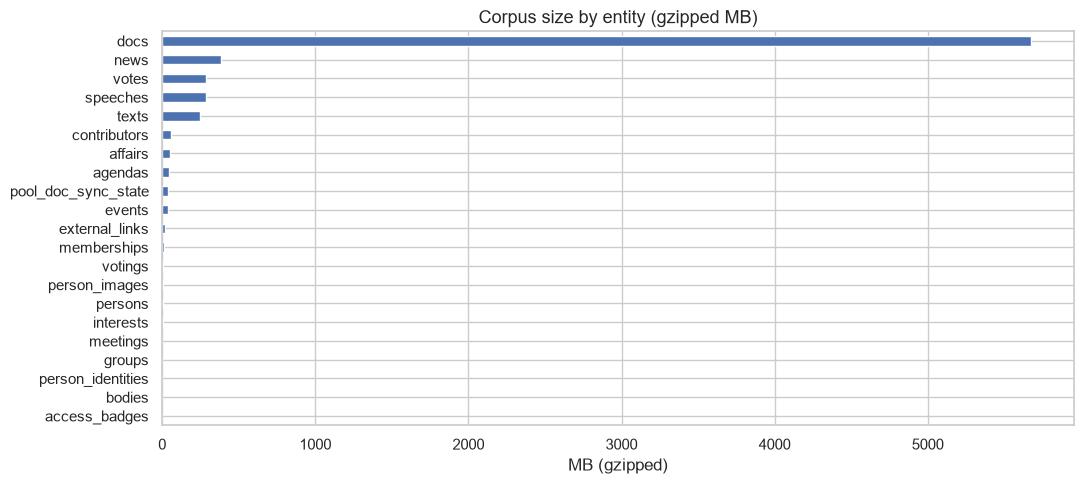

In [3]:
ax = corpus_overview.plot.barh(x="entity", y="size_mb", legend=False,
                                title="Corpus size by entity (gzipped MB)")
ax.invert_yaxis()
ax.set_xlabel("MB (gzipped)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 2. Affairs by parliament

Load `affairs.ndjson.gz` (326k rows, ~49 MB gzipped). This is the master
table of every political affair tracked by OpenParlData. We keep only the
columns needed for downstream aggregation.

In [4]:
t0 = time.perf_counter()
AFFAIRS_PATH = EXPORTS_DIR / "affairs.ndjson.gz"

keep_cols = [
    "id", "body_key", "type_harmonized_en", "begin_date", "end_date",
    "title_de", "title_fr", "title_it", "title_rm",
]
rows = []
for rec in iter_ndjson_gz(AFFAIRS_PATH):
    rows.append({c: rec.get(c) for c in keep_cols})
affairs = pd.DataFrame(rows)
# Replace the "None" string sentinel (OpenParlData exports None as the
# string "None" for some columns) with real NA.
affairs = affairs.replace({"None": pd.NA, "": pd.NA})
affairs["begin_date"] = pd.to_datetime(affairs["begin_date"], errors="coerce")
print(f"Loaded {len(affairs):,} affairs in {time.perf_counter() - t0:.1f}s")
print(f"Date range: {affairs['begin_date'].min()} -> {affairs['begin_date'].max()}")
print(f"Distinct bodies: {affairs['body_key'].nunique()}")
affairs.head(3)

Loaded 326,396 affairs in 6.8s
Date range: 0209-06-15 00:00:00 -> 2026-10-29 00:00:00
Distinct bodies: 89


,id,body_key,type_harmonized_en,begin_date,end_date,title_de,title_fr,title_it,title_rm
0,227258,VD,Postulate,2023-05-30,NaN,NaN,Les BRIO : bilan et perspectives,NaN,NaN
1,178783,VS,Interpellation,2019-11-12,NaN,Beunruhigende Grundwasserverschmutzung (12.11....,Pollution: Un panache qui inquiète! (12.11.201...,NaN,NaN
2,89034,VS,Motion,2019-06-13,NaN,Paritätische Vertretung in den Organen des Gro...,Pour une représentation paritaire au sein des ...,NaN,NaN


In [5]:
affairs_per_body = (
    affairs.groupby("body_key", dropna=False)
    .agg(
        n_affairs=("id", "count"),
        first_affair=("begin_date", "min"),
        last_affair=("begin_date", "max"),
    )
    .sort_values("n_affairs", ascending=False)
)
print(f"Top 20 bodies (out of {len(affairs_per_body)}):")
affairs_per_body.head(20)

Top 20 bodies (out of 89):


,n_affairs,first_affair,last_affair
body_key,,,
CHE,70008,1978-06-05,2026-10-16 00:00:00
BS,21705,1973-03-22,2026-10-15 00:00:00
TI,19722,1985-01-08,2026-10-15 00:00:00
ZH,19345,1987-01-01,2026-10-06 00:00:00
GE,18820,2000-01-04,2026-10-29 00:00:00
6621,9629,1983-12-20,2026-10-27 00:00:00
261,9612,2009-01-07,2026-09-30 00:00:00
VS,8697,2003-11-04,2026-10-16 00:00:00
VD,8338,1950-01-01,2026-10-06 00:00:00


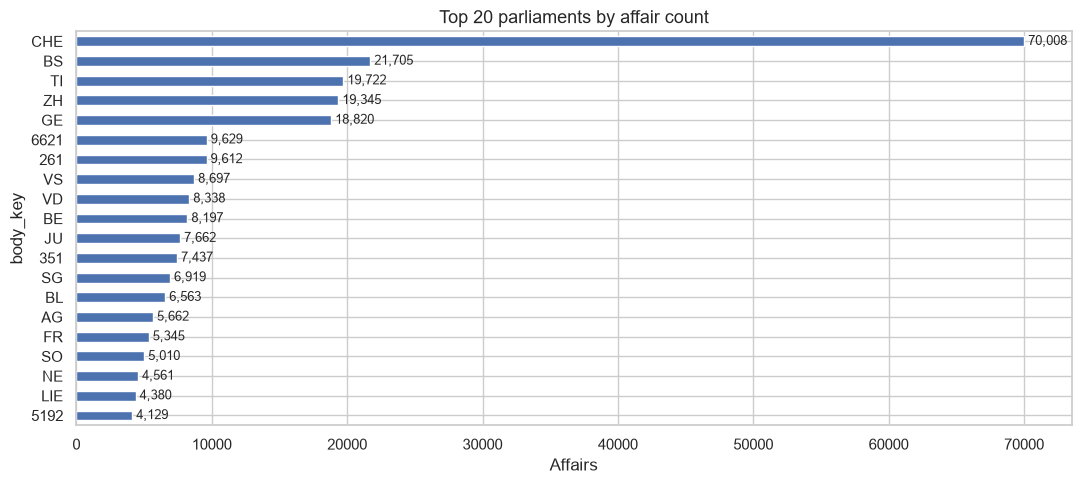

In [6]:
top_n = 20
top_bodies = affairs_per_body.head(top_n)
ax = top_bodies["n_affairs"].plot.barh(title=f"Top {top_n} parliaments by affair count")
ax.invert_yaxis()
ax.set_xlabel("Affairs")
ax.set_ylabel("body_key")
for i, v in enumerate(top_bodies["n_affairs"]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 3. Body × harmonized-type matrix

Cross-tabulate `body_key` × `type_harmonized_en` to see which parliaments
actually use which instrument types. Restricted to the top 15 bodies and
top 10 types for readability.

In [7]:
t0 = time.perf_counter()
body_type = (
    affairs.groupby(["body_key", "type_harmonized_en"], dropna=False)
    .size()
    .rename("n")
    .reset_index()
)
body_type.to_parquet(EDA_OUT / "affairs_by_body_type.parquet", index=False)

top_bodies_list = affairs_per_body.head(15).index.tolist()
top_types_list = (
    affairs["type_harmonized_en"].value_counts().head(10).index.tolist()
)
matrix = (
    body_type[
        body_type["body_key"].isin(top_bodies_list)
        & body_type["type_harmonized_en"].isin(top_types_list)
    ]
    .pivot(index="body_key", columns="type_harmonized_en", values="n")
    .reindex(index=top_bodies_list, columns=top_types_list)
    .fillna(0)
    .astype(int)
)
print(f"Matrix computed in {time.perf_counter() - t0:.2f}s")
matrix

Matrix computed in 6.06s


type_harmonized_en,Question,Interpellation,Government affairs,Motion,Postulate,Question time,Votaziun,Parliamentary initiative,Report,Consultation
body_key,,,,,,,,,,
CHE,4097,18029,2767,13764,6470,17501,1225,3095,0,636
BS,2683,2866,1320,660,2673,0,666,0,1217,78
TI,7229,2532,0,1947,0,0,0,1619,0,13
ZH,7586,736,3391,1102,2657,0,1102,796,371,342
GE,166,0,0,134,1,0,128,0,0,13
6621,1807,563,0,2169,0,0,886,0,0,0
261,2038,295,2205,574,2776,0,402,15,76,0
VS,427,2565,258,1263,2407,342,71,27,23,80
VD,1316,2904,0,712,1016,0,8,0,0,9


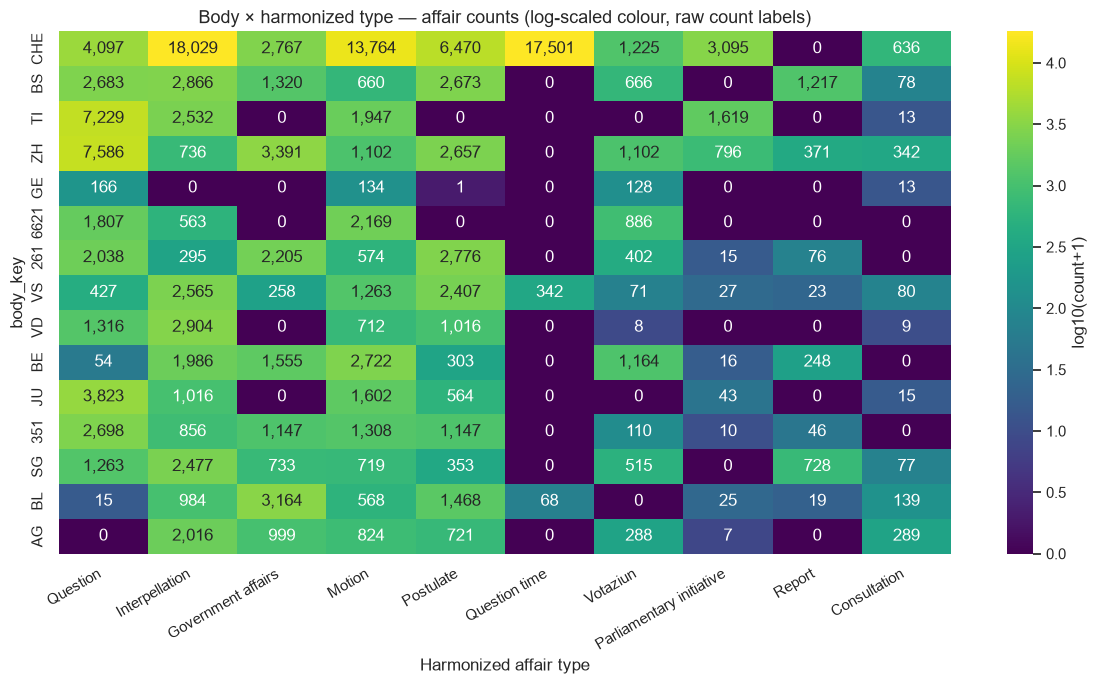

In [8]:
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(
    np.log10(matrix + 1),
    annot=matrix,
    fmt=",",
    cmap="viridis",
    cbar_kws={"label": "log10(count+1)"},
    ax=ax,
)
ax.set_title("Body × harmonized type — affair counts (log-scaled colour, raw count labels)")
ax.set_xlabel("Harmonized affair type")
ax.set_ylabel("body_key")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 4. Language coverage of affair titles

An affair may have titles in any subset of {de, fr, it, rm}. We count
non-null titles per language, grouped by body. Note: this is NOT the
language of full texts (see §6 for that).

In [9]:
lang_cols = ["title_de", "title_fr", "title_it", "title_rm"]
lang_per_body = (
    affairs.groupby("body_key")[lang_cols]
    .apply(lambda df: df.notna().sum())
    .rename(columns={c: c.replace("title_", "titles_") for c in lang_cols})
)
lang_per_body["n_affairs"] = affairs_per_body["n_affairs"]
for col in [c for c in lang_per_body.columns if c.startswith("titles_")]:
    lang_per_body[f"{col}_pct"] = (lang_per_body[col] / lang_per_body["n_affairs"] * 100).round(1)

top_lang = lang_per_body.loc[affairs_per_body.head(15).index]
top_lang

,titles_de,titles_fr,titles_it,titles_rm,n_affairs,titles_de_pct,titles_fr_pct,titles_it_pct,titles_rm_pct
body_key,,,,,,,,,
CHE,69770,69632,69445,0,70008,99.7,99.5,99.2,0.0
BS,21705,0,0,0,21705,100.0,0.0,0.0,0.0
TI,13,0,19722,0,19722,0.1,0.0,100.0,0.0
ZH,19345,0,0,0,19345,100.0,0.0,0.0,0.0
GE,0,18820,0,0,18820,0.0,100.0,0.0,0.0
6621,0,9628,0,0,9629,0.0,100.0,0.0,0.0
261,9612,0,0,0,9612,100.0,0.0,0.0,0.0
VS,8602,8693,0,0,8697,98.9,100.0,0.0,0.0
VD,0,8338,0,0,8338,0.0,100.0,0.0,0.0


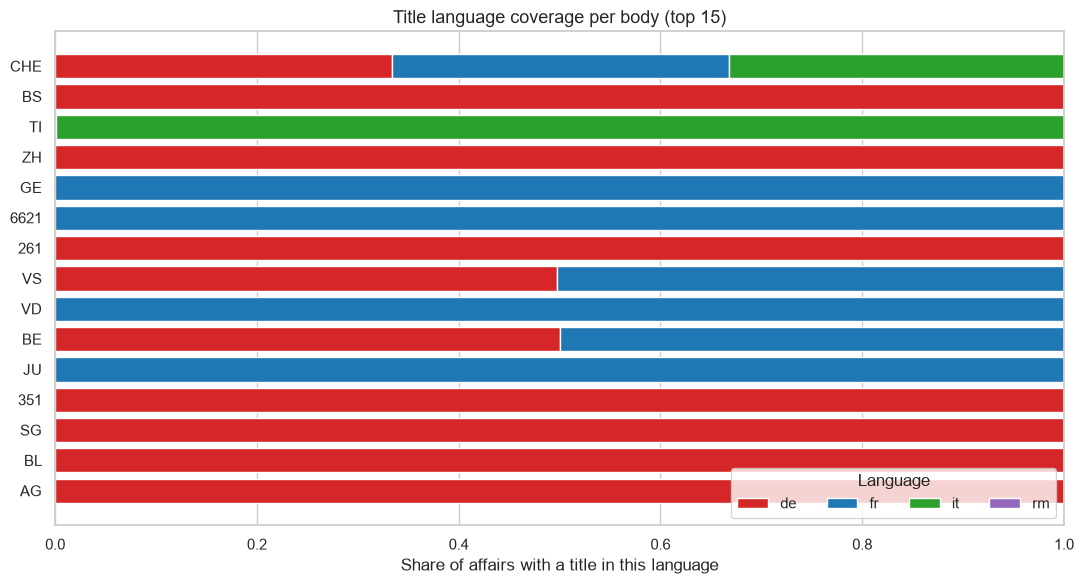

In [10]:
fig, ax = plt.subplots(figsize=(11, 6))
langs = ["titles_de", "titles_fr", "titles_it", "titles_rm"]
labels = ["de", "fr", "it", "rm"]
colors = ["#d62728", "#1f77b4", "#2ca02c", "#9467bd"]
data = top_lang[langs].values
data_pct = data / data.sum(axis=1, keepdims=True)
left = np.zeros(len(top_lang))
for i, (lab, col) in enumerate(zip(labels, colors)):
    ax.barh(top_lang.index, data_pct[:, i], left=left, label=lab, color=col)
    left += data_pct[:, i]
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("Share of affairs with a title in this language")
ax.set_title("Title language coverage per body (top 15)")
ax.legend(title="Language", ncol=4, loc="lower right")
plt.tight_layout()
plt.show()

## 5. Affair-type deep dive

For the top 5 harmonized types (Question, Interpellation, Government
affairs, Motion, Postulate): distribution across bodies and average
title length per language.

In [11]:
top5_types = (
    affairs["type_harmonized_en"].value_counts().head(6).index.tolist()
)
# Drop the None sentinel if present (it represents unharmonized rows)
top5_types = [t for t in top5_types if pd.notna(t)][:5]

for t in top5_types:
    sub = affairs[affairs["type_harmonized_en"] == t]
    print(f"\n=== {t}  ({len(sub):,} affairs, {sub['body_key'].nunique()} bodies) ===")
    print(sub["body_key"].value_counts().head(8).to_string())


=== Question  (55,361 affairs, 74 bodies) ===
body_key
ZH     7586
TI     7229
CHE    4097
JU     3823
LIE    3389
351    2698
BS     2683
261    2038

=== Interpellation  (53,463 affairs, 78 bodies) ===
body_key
CHE    18029
VD      2904
BS      2866
VS      2565
TI      2532
SG      2477
AG      2016
BE      1986

=== Government affairs  (38,054 affairs, 63 bodies) ===
body_key
ZH      3391
BL      3164
CHE     2767
261     2205
BE      1555
3203    1490
SO      1365
BS      1320

=== Motion  (37,455 affairs, 83 bodies) ===
body_key
CHE     13764
BE       2722
6621     2169
TI       1947
JU       1602
351      1308
VS       1263
ZH       1102

=== Postulate  (33,612 affairs, 75 bodies) ===
body_key
CHE     6470
261     2776
BS      2673
ZH      2657
VS      2407
BL      1468
1061    1264
351     1147


In [12]:
# Title length per type, on the German title (most complete)
affairs["title_de_len"] = affairs["title_de"].fillna("").str.len()
title_len = (
    affairs[affairs["type_harmonized_en"].isin(top5_types)]
    .groupby("type_harmonized_en")["title_de_len"]
    .describe()[["count", "mean", "50%", "max"]]
    .rename(columns={"50%": "median"})
    .round(0)
    .astype(int)
)
title_len

,count,mean,median,max
type_harmonized_en,,,,
Government affairs,38054,85,73,607
Interpellation,53463,53,49,667
Motion,37455,54,52,637
Postulate,33612,61,56,500
Question,55361,45,36,804


## 6. Full scan — affair texts

Stream every `texts_*.ndjson.gz` and aggregate `(body_key, text_type,
language)` × length stats. Persisted to
`data/eda/texts_stats.parquet` so re-runs are instant.

Text types come from the source systems (e.g. `Eingereichter Text`,
`Antwort BR / Büro`, `Begründung`). We use `type_de` as the canonical
label because it's the most populated.

In [13]:
TEXTS_CACHE = EDA_OUT / "texts_stats.parquet"
TEXTS_DIR = EXPORTS_DIR / "texts"

if USE_CACHE and TEXTS_CACHE.exists():
    texts_stats = pd.read_parquet(TEXTS_CACHE)
    print(f"Loaded from cache: {TEXTS_CACHE.name} ({len(texts_stats)} rows)")
else:
    t0 = time.perf_counter()
    # key: (body_key, type_de, language)
    accumulators: dict[tuple[str, str, str], LengthAccumulator] = defaultdict(LengthAccumulator)
    total_rows = 0
    files = sorted(TEXTS_DIR.glob("texts_*.ndjson.gz"))
    for fp in files:
        file_rows = 0
        for rec in iter_ndjson_gz(fp):
            body = rec.get("body_key") or "UNKNOWN"
            type_de = rec.get("type_de") or "(untyped)"
            for lang in ("de", "fr", "it", "rm"):
                text = rec.get(f"text_{lang}")
                if text and text != "None":
                    n_chars, _ = text_stats(text)
                    if n_chars > 0:
                        accumulators[(body, type_de, lang)].add(n_chars)
            file_rows += 1
        total_rows += file_rows
        print(f"  {fp.name}: {file_rows:,} rows")
    rows = []
    for (body, type_de, lang), acc in accumulators.items():
        s = acc.summary()
        rows.append({"body_key": body, "type_de": type_de, "language": lang, **s})
    texts_stats = pd.DataFrame(rows)
    texts_stats.to_parquet(TEXTS_CACHE, index=False)
    print(f"Scanned {total_rows:,} text rows in {time.perf_counter() - t0:.1f}s")
    print(f"Wrote {TEXTS_CACHE.name} ({len(texts_stats)} aggregated rows)")

texts_stats.head()

  texts_2581.ndjson.gz: 3,487 rows
  texts_361.ndjson.gz: 771 rows
  texts_4082.ndjson.gz: 678 rows
  texts_5586.ndjson.gz: 1,330 rows
  texts_581.ndjson.gz: 34 rows
  texts_6248.ndjson.gz: 56 rows
  texts_6421.ndjson.gz: 27 rows


  texts_743.ndjson.gz: 508 rows
  texts_AG.ndjson.gz: 543 rows


  texts_CHE.ndjson.gz: 210,437 rows
  texts_FR.ndjson.gz: 93 rows


  texts_LIE.ndjson.gz: 7,472 rows
  texts_LU.ndjson.gz: 116 rows
  texts_NW.ndjson.gz: 114 rows
  texts_OW.ndjson.gz: 67 rows
  texts_TG.ndjson.gz: 93 rows
  texts_UR.ndjson.gz: 141 rows
  texts_VD.ndjson.gz: 7 rows
  texts_ZG.ndjson.gz: 104 rows
Scanned 226,078 text rows in 46.7s
Wrote texts_stats.parquet (325 aggregated rows)


,body_key,type_de,language,count,mean,min,max,p25,p50,p75,p95
0,2581,Beschreibung,de,3486.0,3267.656627,1.0,64853.0,112.0,198.0,4402.0,13694.0
1,361,Beschreibung,de,771.0,842.597925,30.0,4930.0,246.0,647.0,1125.0,2417.0
2,4082,Beschreibung,de,678.0,175.008850,16.0,1286.0,87.0,127.0,214.0,449.0
3,5586,(untyped),fr,1329.0,401.862302,8.0,3839.0,172.0,346.0,516.0,919.0
4,581,Text des Vorstosses,de,17.0,932.411765,198.0,2199.0,444.0,828.0,1171.0,2153.0


In [14]:
# Overall per-body text volume and length (German text as reference)
per_body_de = (
    texts_stats[texts_stats["language"] == "de"]
    .groupby("body_key")
    .agg(total_texts=("count", "sum"), mean_chars=("mean", "mean"), p50_chars=("p50", "mean"))
    .sort_values("total_texts", ascending=False)
)
per_body_de["mean_chars"] = per_body_de["mean_chars"].round(0).astype(int)
per_body_de["p50_chars"] = per_body_de["p50_chars"].round(0).astype(int)
print("Top 15 bodies by German-text volume:")
per_body_de.head(15)

Top 15 bodies by German-text volume:


,total_texts,mean_chars,p50_chars
body_key,,,
CHE,209731.0,1092,847
LIE,7469.0,1755,1576
2581,3486.0,3268,198
361,771.0,843,647
4082,678.0,175,127
AG,543.0,598,539
743,508.0,1507,1285
UR,141.0,1237,1050
LU,116.0,638,577


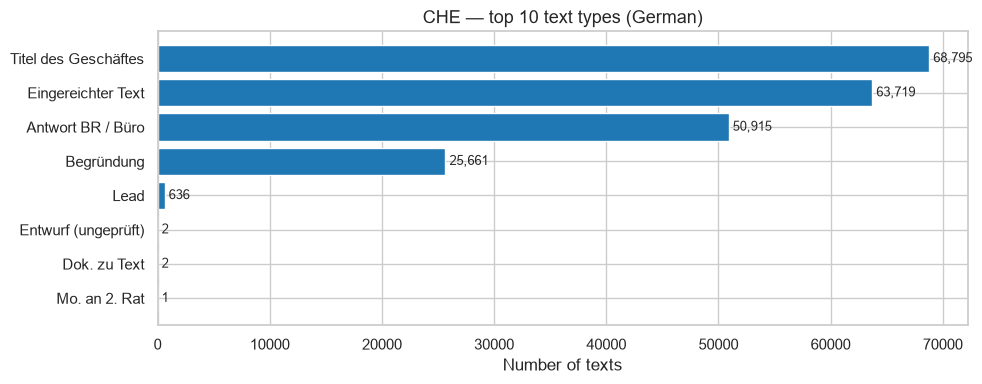

In [15]:
# Text type distribution for CHE (federal)
che_types = (
    texts_stats[(texts_stats["body_key"] == "CHE") & (texts_stats["language"] == "de")]
    .sort_values("count", ascending=False)
    .head(10)
)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(che_types["type_de"], che_types["count"], color="#1f77b4")
ax.invert_yaxis()
ax.set_xlabel("Number of texts")
ax.set_title("CHE — top 10 text types (German)")
for i, v in enumerate(che_types["count"]):
    ax.text(v, i, f" {int(v):,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 7. Full scan — documents

Stream every `docs_*.ndjson.gz` (~5.5 GB gzipped, 910k rows). Each row
represents a document attached to an affair (or news / meeting). Key
fields:

- `format` — MIME type (`application/pdf`, `text/html`, ...)
- `language` — language tag (mostly `de` / `fr` / `it`)
- `size` — original document bytes
- `text` — Tika-extracted text (may be empty for scans)
- `parent_type` — what the doc is attached to (`affair`, `news`, ...)
- `category_harmonized` — broad document category

We aggregate per body: document count, format distribution, language
distribution, size stats, extracted-text length stats.

In [16]:
DOCS_CACHE = EDA_OUT / "docs_stats.parquet"
DOCS_DIR = EXPORTS_DIR / "docs"

if USE_CACHE and DOCS_CACHE.exists():
    docs_stats = pd.read_parquet(DOCS_CACHE)
    print(f"Loaded from cache: {DOCS_CACHE.name} ({len(docs_stats)} rows)")
else:
    t0 = time.perf_counter()
    body_counter: Counter[str] = Counter()
    format_counter: Counter[tuple[str, str]] = Counter()      # (body, format)
    lang_counter: Counter[tuple[str, str]] = Counter()        # (body, language)
    parent_counter: Counter[tuple[str, str]] = Counter()      # (body, parent_type)
    cat_counter: Counter[tuple[str, str]] = Counter()         # (body, category_harmonized)
    size_acc: dict[str, LengthAccumulator] = defaultdict(LengthAccumulator)
    text_len_acc: dict[str, LengthAccumulator] = defaultdict(LengthAccumulator)
    files = sorted(DOCS_DIR.glob("docs_*.ndjson.gz"))
    total_rows = 0
    for i, fp in enumerate(files, 1):
        file_rows = 0
        for rec in iter_ndjson_gz(fp):
            body = rec.get("body_key") or "UNKNOWN"
            body_counter[body] += 1
            fmt = rec.get("format") or "(unknown)"
            format_counter[(body, fmt)] += 1
            lang = rec.get("language") or "(none)"
            lang_counter[(body, lang)] += 1
            parent = rec.get("parent_type") or "(none)"
            parent_counter[(body, parent)] += 1
            cat = rec.get("category_harmonized") or "(uncategorized)"
            cat_counter[(body, cat)] += 1
            size_raw = rec.get("size")
            try:
                size_val = int(size_raw) if size_raw not in (None, "None", "") else 0
            except (TypeError, ValueError):
                size_val = 0
            if size_val > 0:
                size_acc[body].add(size_val)
            text = rec.get("text")
            if text and text != "None":
                n_chars, _ = text_stats(text)
                if n_chars > 0:
                    text_len_acc[body].add(n_chars)
            file_rows += 1
        total_rows += file_rows
        if i % 10 == 0 or i == len(files):
            elapsed = time.perf_counter() - t0
            print(f"  [{i:>3}/{len(files)}] {total_rows:>9,} rows  ({elapsed:.0f}s)")

    # Build a flat DataFrame of per-body aggregates
    rows = []
    for body in body_counter:
        row = {"body_key": body, "n_docs": body_counter[body]}
        row.update({f"size_{k}": v for k, v in size_acc[body].summary().items()})
        row.update({f"text_{k}": v for k, v in text_len_acc[body].summary().items()})
        rows.append(row)
    docs_stats = pd.DataFrame(rows).sort_values("n_docs", ascending=False).reset_index(drop=True)

    # Long-format tables for the dimensional breakdowns
    docs_formats = pd.DataFrame(
        [{"body_key": b, "format": f, "n": n} for (b, f), n in format_counter.items()]
    )
    docs_langs = pd.DataFrame(
        [{"body_key": b, "language": l, "n": n} for (b, l), n in lang_counter.items()]
    )
    docs_parents = pd.DataFrame(
        [{"body_key": b, "parent_type": p, "n": n} for (b, p), n in parent_counter.items()]
    )
    docs_cats = pd.DataFrame(
        [{"body_key": b, "category_harmonized": c, "n": n} for (b, c), n in cat_counter.items()]
    )

    docs_stats.to_parquet(DOCS_CACHE, index=False)
    docs_formats.to_parquet(EDA_OUT / "docs_formats.parquet", index=False)
    docs_langs.to_parquet(EDA_OUT / "docs_langs.parquet", index=False)
    docs_parents.to_parquet(EDA_OUT / "docs_parents.parquet", index=False)
    docs_cats.to_parquet(EDA_OUT / "docs_categories.parquet", index=False)
    print(f"Scanned {total_rows:,} doc rows across {len(files)} files in {time.perf_counter() - t0:.1f}s")
    print(f"Wrote {DOCS_CACHE.name} + 4 dimensional parquets")

# Always reload the long-format tables (cheap even when main stats are cached)
docs_formats = pd.read_parquet(EDA_OUT / "docs_formats.parquet")
docs_langs = pd.read_parquet(EDA_OUT / "docs_langs.parquet")
docs_parents = pd.read_parquet(EDA_OUT / "docs_parents.parquet")
docs_cats = pd.read_parquet(EDA_OUT / "docs_categories.parquet")
docs_stats.head(10)

  [ 10/97]    61,264 rows  (57s)


  [ 20/97]   141,973 rows  (114s)


  [ 30/97]   214,724 rows  (172s)


  [ 40/97]   234,112 rows  (193s)


  [ 50/97]   290,502 rows  (229s)


...

  [ 70/97]   356,679 rows  (308s)


  [ 80/97]   647,783 rows  (1083s)


  [ 90/97]   760,695 rows  (1215s)


  [ 97/97]   910,298 rows  (1409s)
Scanned 910,298 doc rows across 97 files in 1409.6s
Wrote docs_stats.parquet + 4 dimensional parquets


,body_key,n_docs,size_count,size_mean,size_min,size_max,size_p25,size_p50,size_p75,size_p95,text_count,text_mean,text_min,text_max,text_p25,text_p50,text_p75,text_p95
0,BS,66938,66040.0,2.798883e+05,62.0,146427152.0,36182.0,44773.0,78616.0,379784.0,65704.0,11781.035645,19.0,3052625.0,262.0,438.0,3339.0,27526.0
1,CHE,52573,51372.0,1.353905e+06,212.0,512420734.0,76920.0,76920.0,76920.0,377217.0,51761.0,44321.600433,19.0,22653751.0,2409.0,2409.0,2409.0,18394.0
2,261,50306,50300.0,1.852349e+05,21.0,110950237.0,23355.0,53985.0,183705.0,678013.0,48678.0,7110.152882,3.0,2765300.0,432.0,1608.0,4395.0,23775.0
3,BE,49831,49463.0,5.178038e+05,1975.0,205647686.0,97155.0,154928.0,266177.0,1068975.0,48094.0,28230.376533,7.0,6272945.0,2490.0,5463.0,11618.0,69165.0
4,GE,40232,39104.0,1.900010e+06,318.0,598299520.0,155148.0,238506.0,817115.0,7757485.0,39759.0,34948.314922,3.0,5480607.0,3442.0,7596.0,25762.0,140703.0
5,VS,33617,33420.0,2.628934e+05,6051.0,152064308.0,7812.0,39078.0,89175.0,494427.0,33024.0,15565.317678,4.0,3184189.0,1028.0,2185.0,3499.0,18146.0
6,ZH,33157,32329.0,1.514466e+05,3174.0,28734393.0,20684.0,46186.0,125070.0,546398.0,32351.0,17626.143860,19.0,1224017.0,2250.0,5312.0,10766.0,96057.0
7,351,30754,28936.0,3.749816e+05,5264.0,137365255.0,61039.0,75212.0,111776.0,688155.0,28876.0,12744.514025,19.0,3424811.0,650.0,2433.0,7108.0,35728.0
8,BL,29749,27768.0,3.544437e+05,4505.0,31284337.0,42022.0,160666.0,249847.0,829344.0,29634.0,13687.120908,9.0,1163752.0,2040.0,3226.0,10365.0,53063.0
9,GR,25316,23467.0,3.678479e+05,76.0,37725796.0,54217.0,157577.0,401819.0,758241.0,23573.0,55498.235481,13.0,1696684.0,3418.0,5662.0,63637.0,187706.0


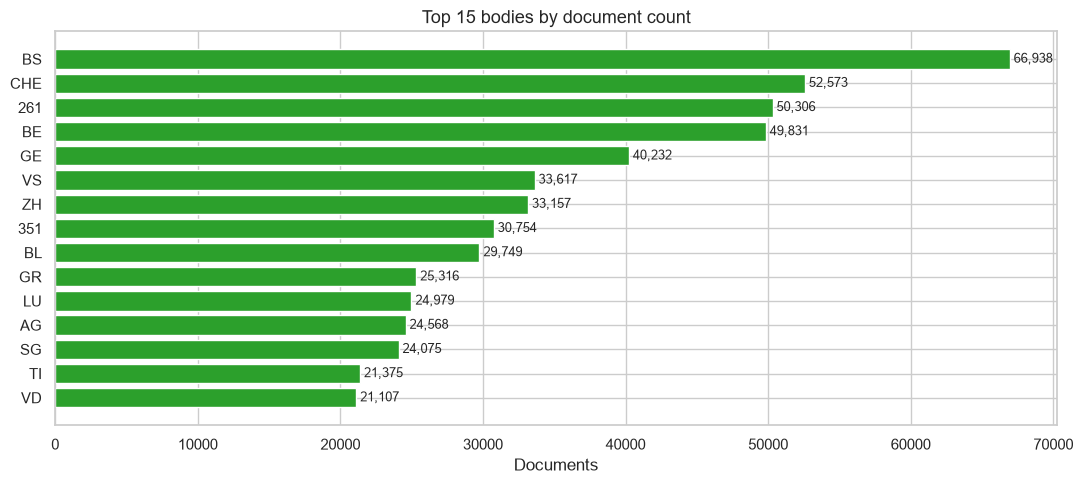

In [17]:
# Top 15 bodies by document count
top = docs_stats.head(15)
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(top["body_key"], top["n_docs"], color="#2ca02c")
ax.invert_yaxis()
ax.set_xlabel("Documents")
ax.set_title("Top 15 bodies by document count")
for i, v in enumerate(top["n_docs"]):
    ax.text(v, i, f" {int(v):,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

Top 10 document formats:
format
application/pdf                                                            712704
(unknown)                                                                   99421
image/jpeg                                                                  41961
pdf                                                                         16396
text/html                                                                   12184
jpg                                                                          5114
video/sonomix                                                                5098
application/zip                                                              4304
PDF                                                                          2933
application/vnd.openxmlformats-officedocument.wordprocessingml.document      2576


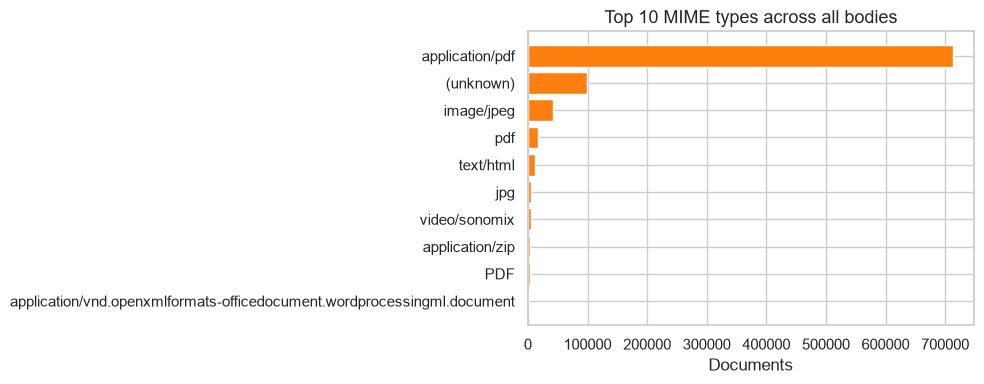

In [18]:
# Document formats across the corpus
top_formats = (
    docs_formats.groupby("format")["n"].sum().sort_values(ascending=False).head(10)
)
print("Top 10 document formats:")
print(top_formats.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(top_formats.index, top_formats.values, color="#ff7f0e")
ax.invert_yaxis()
ax.set_xlabel("Documents")
ax.set_title("Top 10 MIME types across all bodies")
plt.tight_layout()
plt.show()

In [19]:
# Document languages across the corpus
top_langs = (
    docs_langs.groupby("language")["n"].sum().sort_values(ascending=False).head(10)
)
print("Top 10 document languages:")
print(top_langs.to_string())

Top 10 document languages:
language
(none)    532217
de        239177
fr        100312
it         32982
rm          2597
GR          1957
de;fr       1056


In [20]:
# Text-length stats for top bodies (chars of Tika-extracted text)
length_view = docs_stats[["body_key", "n_docs", "text_count", "text_mean", "text_p50", "text_p95"]].head(15).copy()
for c in ["text_count", "text_mean", "text_p50", "text_p95"]:
    length_view[c] = length_view[c].round(0).astype(int)
length_view

,body_key,n_docs,text_count,text_mean,text_p50,text_p95
0,BS,66938,65704,11781,438,27526
1,CHE,52573,51761,44322,2409,18394
2,261,50306,48678,7110,1608,23775
3,BE,49831,48094,28230,5463,69165
4,GE,40232,39759,34948,7596,140703
5,VS,33617,33024,15565,2185,18146
6,ZH,33157,32351,17626,5312,96057
7,351,30754,28876,12745,2433,35728
8,BL,29749,29634,13687,3226,53063
9,GR,25316,23573,55498,5662,187706


## 8. Full scan — speeches

Stream every `speeches_*.ndjson.gz`. Each row is one speaking turn in a
plenary debate, with `text_content_de/fr/it` translations where
available.

In [21]:
SPEECHES_CACHE = EDA_OUT / "speeches_stats.parquet"
SPEECHES_DIR = EXPORTS_DIR / "speeches"

if USE_CACHE and SPEECHES_CACHE.exists():
    speeches_stats = pd.read_parquet(SPEECHES_CACHE)
    print(f"Loaded from cache: {SPEECHES_CACHE.name} ({len(speeches_stats)} rows)")
else:
    t0 = time.perf_counter()
    accumulators: dict[tuple[str, str], LengthAccumulator] = defaultdict(LengthAccumulator)
    files = sorted(SPEECHES_DIR.glob("speeches_*.ndjson.gz"))
    total_rows = 0
    for fp in files:
        file_rows = 0
        for rec in iter_ndjson_gz(fp):
            body = rec.get("body_key") or "UNKNOWN"
            for lang in ("de", "fr", "it"):
                text = rec.get(f"text_content_{lang}")
                if text and text != "None":
                    n_chars, _ = text_stats(text)
                    if n_chars > 0:
                        accumulators[(body, lang)].add(n_chars)
            file_rows += 1
        total_rows += file_rows
        print(f"  {fp.name}: {file_rows:,} rows")
    rows = []
    for (body, lang), acc in accumulators.items():
        s = acc.summary()
        rows.append({"body_key": body, "language": lang, **s})
    speeches_stats = pd.DataFrame(rows)
    speeches_stats.to_parquet(SPEECHES_CACHE, index=False)
    print(f"Scanned {total_rows:,} speech rows in {time.perf_counter() - t0:.1f}s")

speeches_stats.head()

  speeches_351.ndjson.gz: 15,056 rows


  speeches_AI.ndjson.gz: 4,092 rows


  speeches_BE.ndjson.gz: 24,348 rows


  speeches_BS.ndjson.gz: 100,115 rows


  speeches_CHE.ndjson.gz: 337,077 rows
  speeches_GL.ndjson.gz: 8,163 rows


  speeches_JU.ndjson.gz: 11,876 rows


  speeches_SG.ndjson.gz: 3,900 rows


  speeches_TG.ndjson.gz: 22,144 rows


  speeches_ZH.ndjson.gz: 25,792 rows
Scanned 552,563 speech rows in 63.7s


,body_key,language,count,mean,min,max,p25,p50,p75,p95
0,351,de,14055.0,911.009249,11.0,26988.0,71.0,136.0,806.0,4221.0
1,AI,de,1024.0,4255.524414,18.0,263975.0,161.0,419.0,1164.0,4408.0
2,BE,de,20188.0,1426.009164,29.0,25020.0,268.0,1012.0,2050.0,4247.0
3,BS,de,64710.0,590.991732,2.0,43630.0,67.0,113.0,351.0,3493.0
4,CHE,de,201594.0,1852.534981,3.0,47925.0,242.0,1036.0,3049.0,5484.0


In [22]:
per_body_speech = (
    speeches_stats.groupby("body_key")
    .agg(total_speeches=("count", "sum"), mean_chars=("mean", "mean"))
    .sort_values("total_speeches", ascending=False)
)
per_body_speech["mean_chars"] = per_body_speech["mean_chars"].round(0).astype(int)
print("Bodies with speeches in the corpus:")
per_body_speech

Bodies with speeches in the corpus:


,total_speeches,mean_chars
body_key,,
CHE,259876.0,2442
BS,64710.0,591
TG,22144.0,1610
BE,20188.0,1426
351,14055.0,911
JU,11518.0,1329
SG,2383.0,1151
ZH,1207.0,69
AI,1024.0,4256


## 9. Full scan — news

Stream every `news_*.ndjson.gz`. News are press releases and similar
announcements published by parliaments and cantonal governments. Schema
is similar to docs (no consistent `text` payload across bodies — we
aggregate counts and language tags only).

In [23]:
NEWS_CACHE = EDA_OUT / "news_stats.parquet"
NEWS_DIR = EXPORTS_DIR / "news"

if USE_CACHE and NEWS_CACHE.exists():
    news_stats = pd.read_parquet(NEWS_CACHE)
    print(f"Loaded from cache: {NEWS_CACHE.name} ({len(news_stats)} rows)")
else:
    t0 = time.perf_counter()
    # Inspect first row to discover available fields
    first_file = next(NEWS_DIR.glob("news_*.ndjson.gz"))
    sample = next(iter_ndjson_gz(first_file))
    print(f"Sample news keys: {list(sample.keys())}")
    body_counter: Counter[str] = Counter()
    files = sorted(NEWS_DIR.glob("news_*.ndjson.gz"))
    total_rows = 0
    for fp in files:
        for rec in iter_ndjson_gz(fp):
            body = rec.get("body_key") or "UNKNOWN"
            body_counter[body] += 1
            total_rows += 1
    news_stats = (
        pd.DataFrame([{"body_key": b, "n_news": n} for b, n in body_counter.items()])
        .sort_values("n_news", ascending=False)
        .reset_index(drop=True)
    )
    news_stats.to_parquet(NEWS_CACHE, index=False)
    print(f"Scanned {total_rows:,} news rows in {time.perf_counter() - t0:.1f}s")

print(f"Bodies with news: {len(news_stats)}")
news_stats.head(10)

Sample news keys: ['id', 'date', 'body_id', 'contact', 'lead_de', 'lead_en', 'lead_fr', 'lead_it', 'lead_rm', 'type_de', 'type_en', 'type_fr', 'type_it', 'type_rm', 'version', 'body_key', 'location', 'title_de', 'title_en', 'title_fr', 'title_it', 'title_rm', 'affair_id', 'image_url', 'content_de', 'content_en', 'content_fr', 'content_it', 'content_rm', 'created_at', 'updated_at', 'external_id', 'affair_number', 'content_format', 'additional_data', 'type_harmonized', 'url_external_de', 'url_external_en', 'url_external_fr', 'url_external_it', 'url_external_rm', 'affair_external_id', 'updated_external_at']


Scanned 339,562 news rows in 31.3s
Bodies with news: 293


,body_key,n_news
0,CHE,54675
1,GE,26081
2,SG,24461
3,ZH,22207
4,BS,18541
5,TG,16948
6,UR,13369
7,LU,10286
8,AG,10246
9,FR,8830


## 10. Subject areas — labelled subset

The HackApertus challenge provides labels for a subset of parliaments.
Each parliament uses its **own** scheme — these are NOT harmonized:

- **CHE (federal)** — Curia Vista: 28 subject areas (multi-label,
  ~2 per affair) + fine-grained descriptors (German-only, 1996–2014)
- **SG (St. Gallen)** — 10 subject areas, one per affair
- **TG (Thurgau)** — 118 subject areas with systematic codes
- **1711 (Stadt Zug)** — 37 departments (administrative units)
- **ZH (Zürich)** — 724 free keywords (consultations only)

We load each and show its distribution.

In [24]:
# CHE: Curia Vista subject areas
che_vocab = pd.read_csv(HACK_DIR / "che_topics_vocabulary.csv")
print(f"CHE vocabulary: {len(che_vocab)} subject areas")
print(che_vocab.columns.tolist())
che_vocab

CHE vocabulary: 28 subject areas
['topic_id', 'topic_de', 'topic_fr', 'topic_it', 'affairs']


,topic_id,topic_de,topic_fr,topic_it,affairs
0,15,Wirtschaft,Économie,Economia,11023
1,2841,Gesundheit,Santé,Salute,10273
2,4,Staatspolitik,Politique d'Etat,Politica nazionale,8855
3,24,Finanzwesen,Finances,Finanze,8488
4,52,Umwelt,Environnement,Ambiente,7596
5,8,Internationale Politik,Politique internationale,Politica internazionale,7342
6,28,Soziale Fragen,Questions sociales,Questioni sociali,6977
7,9,Sicherheitspolitik,Politique de sécurité,Politica di sicurezza,6651
8,48,Verkehr,Transports,Trasporti,6548
9,2811,Migration,Politique migratoire,Migrazione,4827


In [25]:
che_kw = pd.read_csv(HACK_DIR / "che_affairs_keywords.csv")
print(f"CHE labelled affairs: {len(che_kw):,}")
print(f"Columns: {che_kw.columns.tolist()}")
che_kw.head(3)

CHE labelled affairs: 70,008
Columns: ['openparldata_id', 'affair_external_id', 'number', 'type_en', 'type_de', 'begin_date', 'title_de', 'title_fr', 'title_it', 'url', 'topic_ids', 'topics_de', 'topics_fr', 'topics_it', 'descriptors_de']


C:\Users\Swiss_SDI\AppData\Local\Temp\ipykernel_30788\104227076.py:1: DtypeWarning: Columns (1: affair_external_id, 2: number, 14: descriptors_de) have mixed types. Specify dtype option on import or set low_memory=False.
  che_kw = pd.read_csv(HACK_DIR / "che_affairs_keywords.csv")


,openparldata_id,affair_external_id,number,type_en,type_de,begin_date,title_de,title_fr,title_it,url,topic_ids,topics_de,topics_fr,topics_it,descriptors_de
0,71961,19780222,78.222,Parliamentary initiative,Parlamentarische Initiative,1978-06-05,Strafgesetzbuch. Schwangerschaftsabbruch (Gira...,Code pénal. Interruption de la grossesse (Gira...,Rapporto della Commissione del 27.08.1979,https://www.parlament.ch/de/ratsbetrieb/suche-...,NaN,NaN,NaN,NaN,NaN
1,162471,19800226,80.226,Parliamentary initiative,Parlamentarische Initiative,1980-06-02,BV. Unternehmensrecht (Jelmini),Constitutiion fédérale. Droit de l'entreprise ...,Constitutiion fédérale. Droit de l'entreprise ...,https://www.parlament.ch/de/ratsbetrieb/suche-...,NaN,NaN,NaN,NaN,Rechtsform einer Gesellschaft
2,71962,19850019,85.019,Government affairs,Geschäft des Bundesrates,1985-05-01,Friedliche Nutzung der Kernenergie. Abkommen m...,Utilisation pacifique de l'énergie nucléaire. ...,Utilisation pacifique de l'énergie nucléaire. ...,https://www.parlament.ch/de/ratsbetrieb/suche-...,NaN,NaN,NaN,NaN,NaN


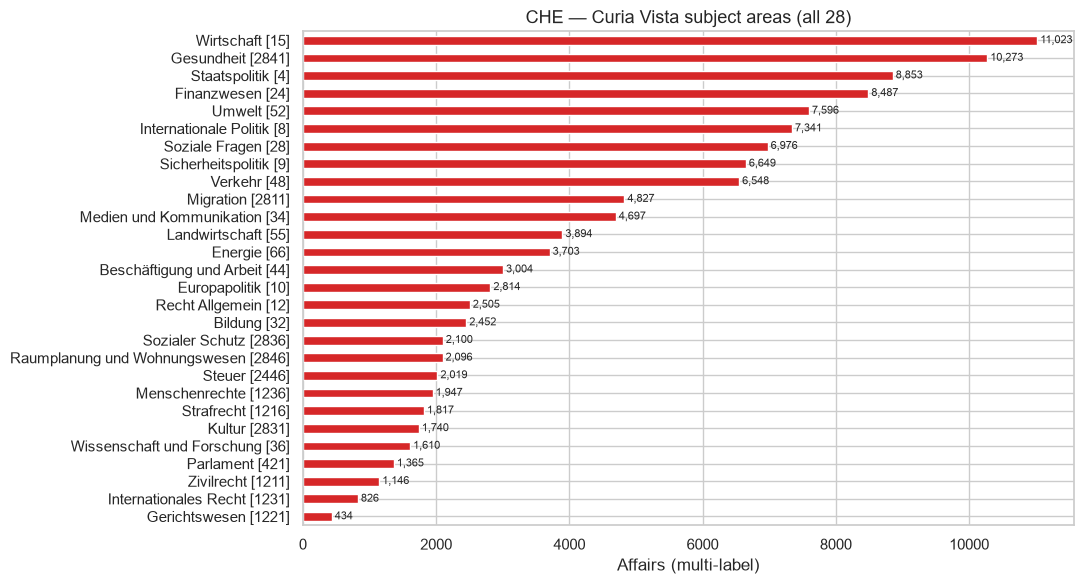

In [26]:
# Distribution of subject-area IDs (multi-valued, |-separated)
topic_lists = che_kw["topic_ids"].dropna().astype(str).str.split(r"\s*\|\s*")
topic_counts = Counter()
for lst in topic_lists:
    for tid in lst:
        if tid and tid != "None":
            topic_counts[tid.strip()] += 1

# Map ID -> German name via the vocabulary
vocab_lookup = dict(zip(che_vocab["topic_id"].astype(str), che_vocab["topic_de"]))
topic_series = pd.Series(topic_counts).sort_values(ascending=False)
topic_series.index = topic_series.index.map(lambda tid: f"{vocab_lookup.get(tid, tid)} [{tid}]")

fig, ax = plt.subplots(figsize=(11, 6))
topic_series.plot.barh(ax=ax, color="#d62728")
ax.invert_yaxis()
ax.set_xlabel("Affairs (multi-label)")
ax.set_title("CHE — Curia Vista subject areas (all 28)")
for i, v in enumerate(topic_series.values):
    ax.text(v, i, f" {int(v):,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

In [27]:
# Cantonal schemes
cant_kw = pd.read_csv(HACK_DIR / "cantonal_affairs_keywords.csv")
cant_vocab = pd.read_csv(HACK_DIR / "cantonal_keywords_vocabulary.csv")
print(f"Cantonal labelled affairs: {len(cant_kw):,}")
print(f"Cantonal vocabulary entries: {len(cant_vocab):,}")
print(f"Bodies: {sorted(cant_kw['body_key'].unique())}")
print(cant_kw.groupby("body_key").size())

Cantonal labelled affairs: 10,742
Cantonal vocabulary entries: 889
Bodies: ['1711', 'SG', 'TG', 'ZH']
body_key
1711    1343
SG      6792
TG      2382
ZH       225
dtype: int64


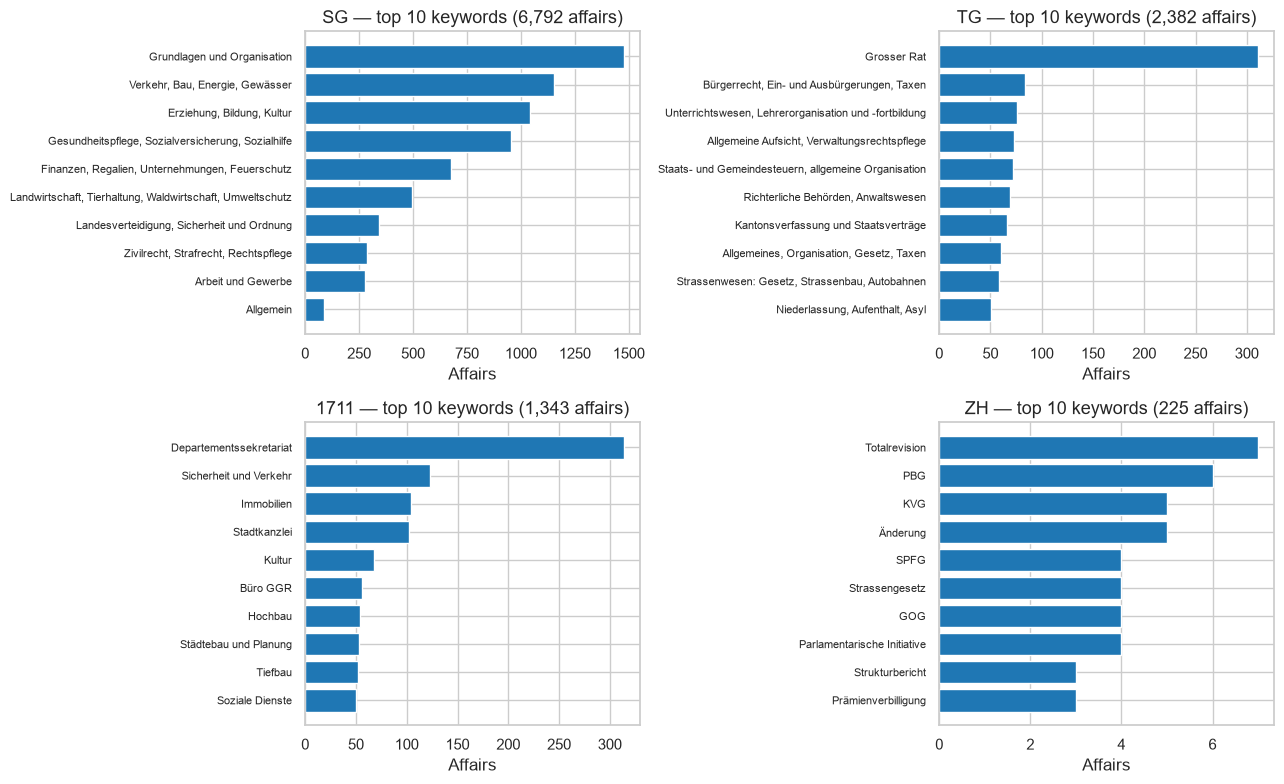

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, body in zip(axes.flat, ["SG", "TG", "1711", "ZH"]):
    sub = cant_kw[cant_kw["body_key"] == body]
    kws = (
        sub["keywords"].dropna().astype(str).str.split(r"\s*\|\s*")
    )
    counts = Counter()
    for lst in kws:
        for kw in lst:
            if kw and kw != "None":
                counts[kw.strip()] += 1
    top = pd.Series(counts).sort_values(ascending=False).head(10)
    ax.barh(top.index[::-1], top.values[::-1], color="#1f77b4")
    ax.set_title(f"{body} — top 10 keywords ({len(sub):,} affairs)")
    ax.set_xlabel("Affairs")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

## 11. DVS use case — digitalisation

The PolitMonitor file contains 3,433 affairs editorially tagged as
"Digitalisierung" across 35 parliaments (mostly 2018–2026). It is our
positive set for the DVS use case. We look at its body/time/language
distribution.

In [29]:
pm = pd.read_csv(HACK_DIR / "politmonitor_digitalisierung.csv")
pm["begin_date"] = pd.to_datetime(pm["begin_date"], errors="coerce")
print(f"PolitMonitor digitalisation affairs: {len(pm):,}")
print(f"Columns: {pm.columns.tolist()}")
print(f"Bodies: {pm['body_key'].nunique()}")
print(f"Year range: {pm['begin_date'].dt.year.min()} -> {pm['begin_date'].dt.year.max()}")
pm.head(3)

PolitMonitor digitalisation affairs: 3,433
Columns: ['openparldata_id', 'body_key', 'number', 'begin_date', 'type_en', 'title_de', 'title_fr', 'title_it', 'url', 'politmonitor_scope', 'politmonitor_id', 'topic']
Bodies: 35
Year range: 2009 -> 2026


,openparldata_id,body_key,number,begin_date,type_en,title_de,title_fr,title_it,url,politmonitor_scope,politmonitor_id,topic
0,152141,CHE,17.3199,2017-03-16,Motion,Ausbau der Cyberabwehrkompetenzen,Développement des compétences en matière de cy...,Ampliare le competenze nell'ambito della cyber...,https://www.parlament.ch/de/ratsbetrieb/suche-...,ch,20173199,Digitalisierung
1,152620,CHE,17.4231,2017-12-15,Interpellation,Online-Verkauf von Medikamenten. Öffnung im In...,Vente de médicaments en ligne. Une ouverture d...,Vendita di medicamenti on-line. Un'apertura ne...,https://www.parlament.ch/de/ratsbetrieb/suche-...,ch,20174231,Digitalisierung
2,153147,CHE,18.3006,2018-01-29,Motion,Den Kollaps der Mobilfunknetze verhindern und ...,Eviter l'effondrement des réseaux de téléphoni...,Evitare il collasso delle reti di telefonia mo...,https://www.parlament.ch/de/ratsbetrieb/suche-...,ch,20183006,Digitalisierung


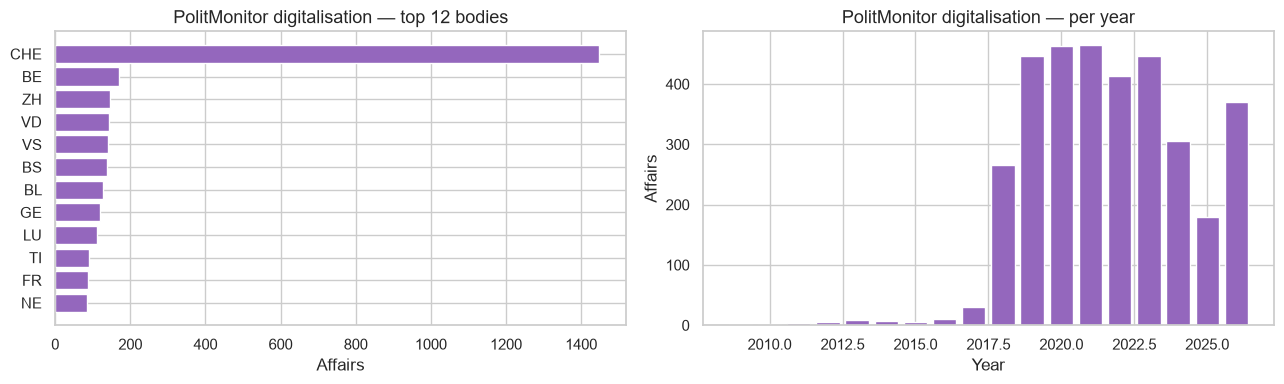

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# By body (top 12)
by_body = pm["body_key"].value_counts().head(12)
axes[0].barh(by_body.index, by_body.values, color="#9467bd")
axes[0].invert_yaxis()
axes[0].set_title("PolitMonitor digitalisation — top 12 bodies")
axes[0].set_xlabel("Affairs")

# By year
by_year = pm.groupby(pm["begin_date"].dt.year).size()
axes[1].bar(by_year.index, by_year.values, color="#9467bd")
axes[1].set_title("PolitMonitor digitalisation — per year")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Affairs")
plt.tight_layout()
plt.show()

In [31]:
# DVS small reference set
dvs = pd.read_csv(HACK_DIR / "dvs_digitalisierung.csv")
print(f"DVS list: {len(dvs)} affairs across {dvs['body_key'].nunique()} bodies")
print(dvs["body_key"].value_counts().to_string())
overlap = pm["openparldata_id"].isin(dvs["openparldata_id"]).sum()
print(f"Overlap DVS ∩ PolitMonitor: {overlap} / {len(dvs)}")

DVS list: 30 affairs across 10 bodies
body_key
BE     12
CHE     5
ZG      3
OW      3
TG      2
ZH      1
AG      1
BL      1
VS      1
GE      1
Overlap DVS ∩ PolitMonitor: 29 / 30


## 12. Cross-view — subject × affair type (CHE)

For the federal parliament only, how do Curia Vista subject areas
co-occur with harmonized affair types? E.g., are Motions about
"Bildung" as common as Interpellations about "Gesundheit"?

In [32]:
# Join CHE keywords to affairs to get harmonized type
che_kw_small = che_kw[["openparldata_id", "topic_ids"]].copy()
che_join = che_kw_small.merge(
    affairs[["id", "type_harmonized_en"]],
    left_on="openparldata_id",
    right_on="id",
    how="left",
)
print(f"Joined {len(che_join):,} CHE affairs ({che_join['type_harmonized_en'].notna().sum():,} with harmonized type)")

# Expand multi-label topics
rows = []
for rec in che_join.itertuples(index=False):
    tids = rec.topic_ids
    if pd.isna(tids):
        continue
    for tid in str(tids).split("|"):
        tid = tid.strip()
        if tid and tid != "None":
            rows.append({
                "topic_id": tid,
                "type_harmonized_en": rec.type_harmonized_en,
            })
che_long = pd.DataFrame(rows)
print(f"Expanded to {len(che_long):,} (affair × topic) rows")

Joined 70,008 CHE affairs (69,310 with harmonized type)


Expanded to 118,742 (affair × topic) rows


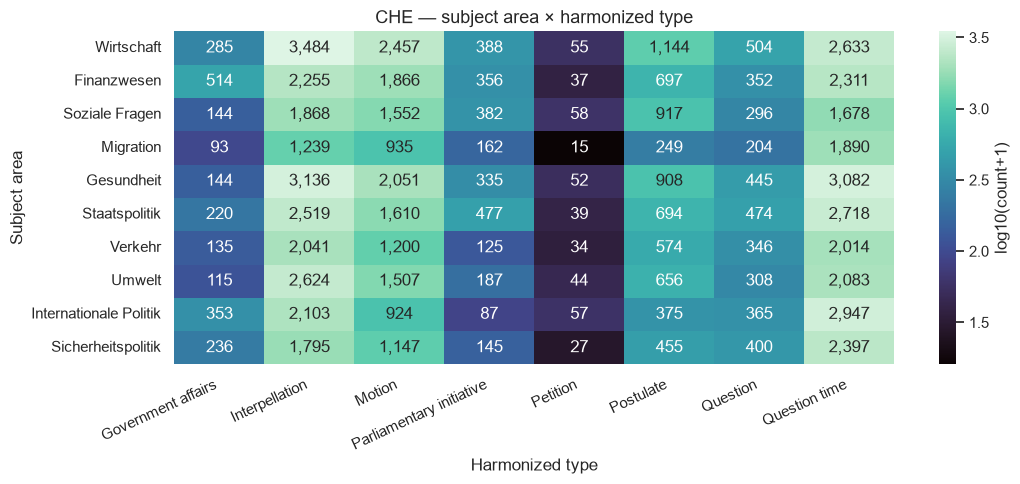

In [33]:
# Top 10 topics × top 8 harmonized types, heatmap
top10_topic_ids = (
    che_long["topic_id"].value_counts().head(10).index.tolist()
)
top8_types = (
    che_long["type_harmonized_en"].value_counts().head(8).index.tolist()
)
mat = (
    che_long[
        che_long["topic_id"].isin(top10_topic_ids)
        & che_long["type_harmonized_en"].isin(top8_types)
    ]
    .groupby(["topic_id", "type_harmonized_en"]).size()
    .unstack(fill_value=0)
)
# Use topic names
mat.index = [f"{vocab_lookup.get(t, t)}" for t in mat.index]

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    np.log10(mat + 1),
    annot=mat, fmt=",",
    cmap="mako",
    cbar_kws={"label": "log10(count+1)"},
    ax=ax,
)
ax.set_title("CHE — subject area × harmonized type")
ax.set_xlabel("Harmonized type")
ax.set_ylabel("Subject area")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 13. APS target scheme

The Année Politique Suisse (APS) scheme is the **zero-shot target** for
the classification service: 8 domains, 22 chapters, 165 topics. We load
it here so the shape of the target is explicit.

In [34]:
aps_path = HACK_DIR / "aps_topics.xlsx"
aps_topics = pd.read_excel(aps_path, sheet_name="Topics")
aps_chapters = pd.read_excel(aps_path, sheet_name="Chapters")
aps_domains = pd.read_excel(aps_path, sheet_name="Domains")
print(f"APS: {len(aps_domains)} domains, {len(aps_chapters)} chapters, {len(aps_topics)} topics")
print(f"Topics columns: {aps_topics.columns.tolist()}")
aps_domains

APS: 8 domains, 22 chapters, 165 topics
Topics columns: ['code', 'domain_de', 'domain_fr', 'chapter_de', 'chapter_fr', 'topic_de', 'topic_fr', 'url_de']


,code,domain_de,domain_fr,url_de
0,1,Akteure und Institutionen,Institutions et acteurs,https://anneepolitique.swiss/de/themen/
1,2,Direkte Demokratie und Wahlen,Démocratie directe et élections,https://anneepolitique.swiss/de/themen/
2,3,Europa- und Aussenpolitik,Politique européenne et étrangère,https://anneepolitique.swiss/de/themen/
3,4,Gesellschaft und Kultur,Société et culture,https://anneepolitique.swiss/de/themen/
4,5,Gesundheit und Sozialsystem,Santé et système social,https://anneepolitique.swiss/de/themen/
5,6,Infrastruktur und Umwelt,Infrastructures et environnement,https://anneepolitique.swiss/de/themen/
6,7,Rechts- und Sicherheitspolitik,Politique juridique et de sécurité,https://anneepolitique.swiss/de/themen/
7,8,Wirtschaft und Finanzen,Economie et finances,https://anneepolitique.swiss/de/themen/


In [35]:
# Topics per chapter
topics_per_chapter = (
    aps_topics.groupby(["chapter_de", "domain_de"]).size().rename("n_topics").reset_index()
    .sort_values(["domain_de", "n_topics"], ascending=[True, False])
)
print("Topics per chapter (grouped by domain):")
topics_per_chapter.head(25)

Topics per chapter (grouped by domain):


,chapter_de,domain_de,n_topics
7,Institutionen,Akteure und Institutionen,12
11,Politische Grundfragen,Akteure und Institutionen,4
2,Direkte Demokratie,Direkte Demokratie und Wahlen,9
19,Wahlen,Direkte Demokratie und Wahlen,4
4,Europa- und Aussenpolitik,Europa- und Aussenpolitik,8
15,Soziale Gruppen,Gesellschaft und Kultur,10
1,Bildung und Forschung,Gesellschaft und Kultur,5
8,"Kultur, Sprache, Kirchen",Gesellschaft und Kultur,5
10,Medien,Gesellschaft und Kultur,5
16,Sozialversicherungen,Gesundheit und Sozialsystem,11


## Summary

Print a compact recap of what was computed and where outputs live.
This cell is the canonical record per AGENTS.md §6.

In [36]:
summary = {
    "Affairs loaded (master)": f"{len(affairs):,}",
    "Distinct bodies (affairs)": affairs["body_key"].nunique(),
    "Texts aggregated rows": len(texts_stats),
    "Docs aggregated rows": len(docs_stats),
    "Speeches aggregated rows": len(speeches_stats),
    "News aggregated rows": len(news_stats),
    "CHE labelled affairs": f"{len(che_kw):,}",
    "Cantonal labelled affairs": f"{len(cant_kw):,}",
    "PolitMonitor digitalisation": f"{len(pm):,}",
    "DVS list": len(dvs),
    "APS topics": len(aps_topics),
}
summary_df = pd.Series(summary, name="value").to_frame()
print(summary_df.to_string())
print()
print("Output artefacts under data/eda/:")
for p in sorted(EDA_OUT.glob("*.parquet")):
    size_kb = p.stat().st_size / 1024
    print(f"  {p.name:40s} {size_kb:>10.1f} KB")
print()
print("Next steps: 02_baseline.ipynb — Apertus zero-shot classification on the labelled sample.")


                               value
Affairs loaded (master)      326,396
Distinct bodies (affairs)         89
Texts aggregated rows            325
Docs aggregated rows              97
Speeches aggregated rows          12
News aggregated rows             293
CHE labelled affairs          70,008
Cantonal labelled affairs     10,742
PolitMonitor digitalisation    3,433
DVS list                          30
APS topics                       165

Output artefacts under data/eda/:
  affairs_by_body_type.parquet                    6.0 KB
  docs_categories.parquet                         5.8 KB
  docs_formats.parquet                            5.7 KB
  docs_langs.parquet                              3.9 KB
  docs_parents.parquet                            4.5 KB
  docs_stats.parquet                             21.4 KB
  news_stats.parquet                              3.9 KB
  speeches_stats.parquet                          6.4 KB
  texts_stats.parquet                            22.0 KB

Next st